# 01 – Exploratory Data Analysis (Telco churn)
Goal: understand who churns and why, before modelling. Descriptive only: no model fitting here.

In [1]:
# Setup
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def find_repo_root() -> Path:
    """Walk up from the current folder until configs/config.yaml is found."""
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        if (folder / "configs" / "config.yaml").exists():
            return folder
    raise FileNotFoundError("Could not find configs/config.yaml. Open the repo folder in VS Code.")


ROOT = find_repo_root()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

from src.config import load_config  # noqa: E402

cfg = load_config()
np.random.seed(cfg["project"]["random_seed"])
TARGET = cfg["data"]["target"]

data_path = Path(cfg["paths"]["processed_data"])
if not data_path.exists():
    raise FileNotFoundError(f"{data_path} not found. Run `python -m src.data` first.")
df = pd.read_csv(data_path)

FIG_DIR = Path(cfg["paths"]["reports_dir"]) / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
overall = df[TARGET].mean()
print(f"Loaded {df.shape[0]} rows x {df.shape[1]} columns. Overall churn rate: {overall:.3f}")

Loaded 7043 rows x 21 columns. Overall churn rate: 0.265


In [2]:
# First look
display(df.head())
display(df.dtypes.to_frame("dtype").T)
display(df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2))
print("Churn counts:\n", df[TARGET].value_counts())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,...,str,str,str,str,str,str,str,float64,float64,int64


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


Churn counts:
 Churn
0    5174
1    1869
Name: count, dtype: int64


In [3]:
# a helper for “churn rate by group”
def churn_by(col: str, min_count: int = 30) -> pd.DataFrame:
    """Customers and churn rate per group. Warns about groups too small to trust."""
    table = (
        df.groupby(col, observed=True)[TARGET]
        .agg(customers="size", churn_rate="mean")
        .reset_index()
    )
    table["churn_rate"] = table["churn_rate"].round(3)
    small = table[table["customers"] < min_count]
    if not small.empty:
        print(f"WARNING: groups with fewer than {min_count} customers in '{col}':")
        print(small.to_string(index=False))
    return table.sort_values("churn_rate", ascending=False).reset_index(drop=True)

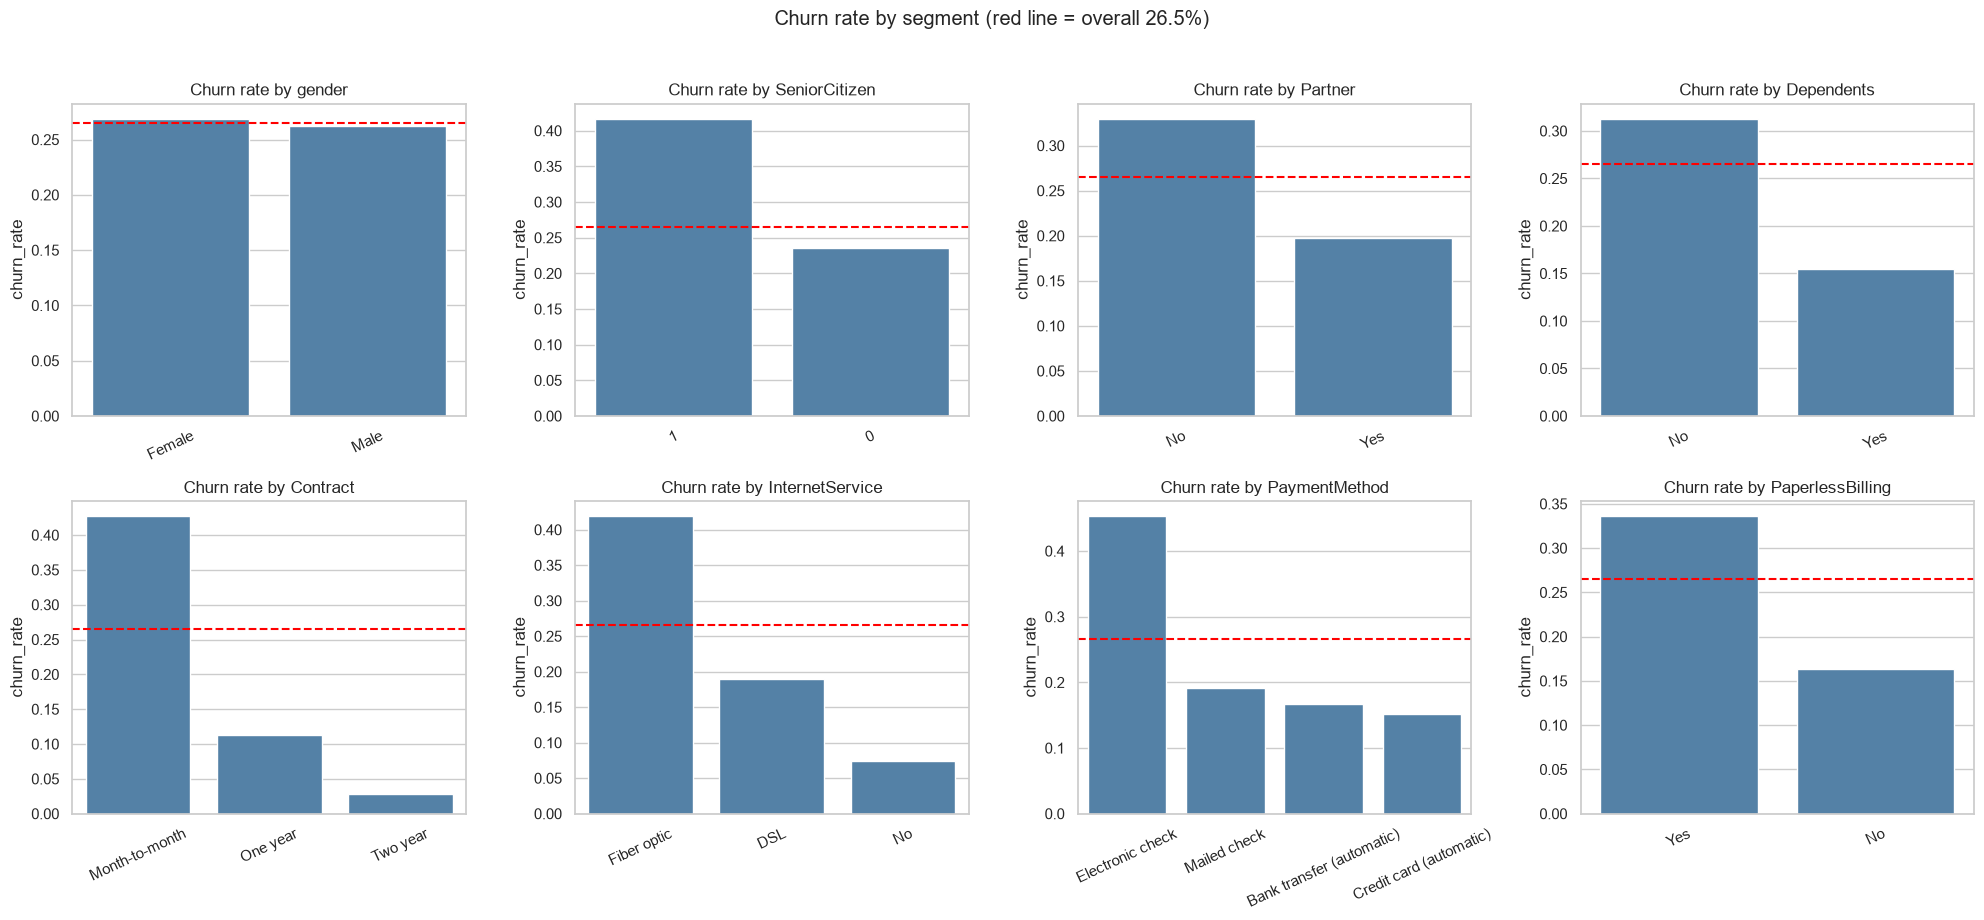


--- gender ---
gender  customers  churn_rate
Female       3488       0.269
  Male       3555       0.262

--- SeniorCitizen ---
 SeniorCitizen  customers  churn_rate
             1       1142       0.417
             0       5901       0.236

--- Partner ---
Partner  customers  churn_rate
     No       3641       0.330
    Yes       3402       0.197

--- Dependents ---
Dependents  customers  churn_rate
        No       4933       0.313
       Yes       2110       0.155

--- Contract ---
      Contract  customers  churn_rate
Month-to-month       3875       0.427
      One year       1473       0.113
      Two year       1695       0.028

--- InternetService ---
InternetService  customers  churn_rate
    Fiber optic       3096       0.419
            DSL       2421       0.190
             No       1526       0.074

--- PaymentMethod ---
            PaymentMethod  customers  churn_rate
         Electronic check       2365       0.453
             Mailed check       1612       0.191
Bank

In [4]:
# churn by customer segment
cat_cols = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "Contract", "InternetService", "PaymentMethod", "PaperlessBilling",
]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.ravel(), cat_cols, strict=True):
    table = churn_by(col)
    table[col] = table[col].astype(str)
    sns.barplot(data=table, x=col, y="churn_rate", ax=ax, color="steelblue")
    ax.axhline(overall, ls="--", color="red")
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
fig.suptitle(f"Churn rate by segment (red line = overall {overall:.1%})", y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / "churn_by_segment.png", dpi=150, bbox_inches="tight")
plt.show()

for col in cat_cols:
    print(f"\n--- {col} ---")
    print(churn_by(col).to_string(index=False))

tenure_bucket  customers  churn_rate
          0-6       1481       0.529
         7-12        705       0.359
        13-24       1024       0.287
        25-48       1594       0.204
          49+       2239       0.095


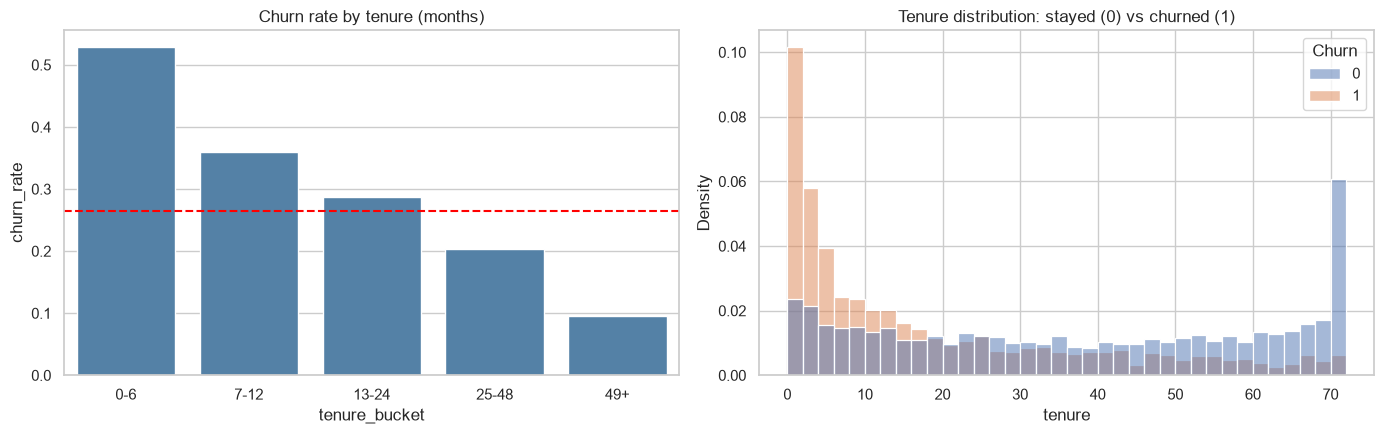

In [5]:
# tenure 
df["tenure_bucket"] = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, np.inf],
    labels=["0-6", "7-12", "13-24", "25-48", "49+"],
)
tenure_table = churn_by("tenure_bucket").sort_values("tenure_bucket")
print(tenure_table.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=tenure_table, x="tenure_bucket", y="churn_rate", ax=axes[0], color="steelblue")
axes[0].axhline(overall, ls="--", color="red")
axes[0].set_title("Churn rate by tenure (months)")
sns.histplot(
    data=df, x="tenure", hue=TARGET, bins=36, stat="density", common_norm=False, ax=axes[1]
)
axes[1].set_title("Tenure distribution: stayed (0) vs churned (1)")
plt.tight_layout()
fig.savefig(FIG_DIR / "tenure.png", dpi=150, bbox_inches="tight")
plt.show()

charge_quartile  customers  churn_rate
    Q1 (lowest)       1762       0.112
             Q2       1766       0.246
             Q3       1757       0.375
   Q4 (highest)       1758       0.329


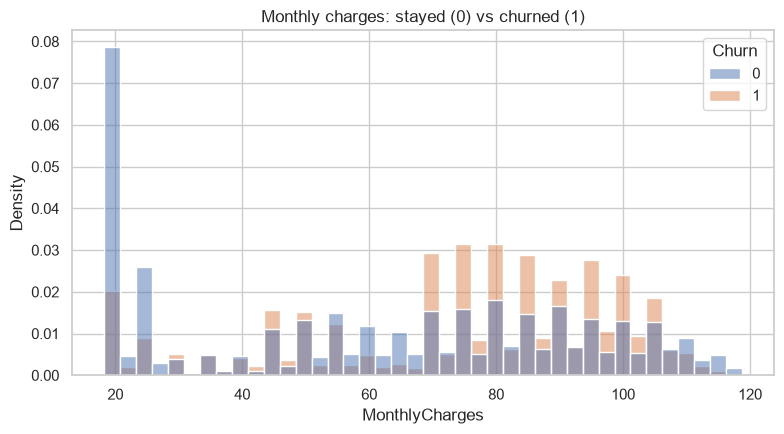

In [6]:
# monthly charges 
df["charge_quartile"] = pd.qcut(
    df["MonthlyCharges"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]
)
print(churn_by("charge_quartile").sort_values("charge_quartile").to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(
    data=df, x="MonthlyCharges", hue=TARGET, bins=40, stat="density", common_norm=False, ax=ax
)
ax.set_title("Monthly charges: stayed (0) vs churned (1)")
plt.tight_layout()
fig.savefig(FIG_DIR / "monthly_charges.png", dpi=150, bbox_inches="tight")
plt.show()

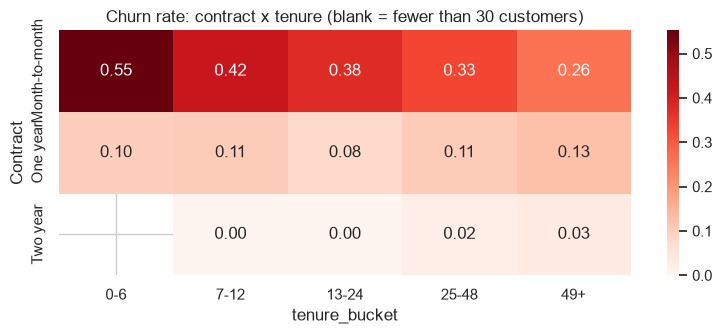

Customers per cell:


tenure_bucket,0-6,7-12,13-24,25-48,49+
Contract,,,,,
Month-to-month,1413,581,737,802,342
One year,39,85,197,518,634
Two year,29,39,90,274,1263


In [7]:
# contract and tenure together
rates = df.pivot_table(
    index="Contract", columns="tenure_bucket", values=TARGET, aggfunc="mean", observed=True
)
counts = df.pivot_table(
    index="Contract", columns="tenure_bucket", values=TARGET, aggfunc="size", observed=True
)
rates = rates.where(counts >= 30)  # hide cells with fewer than 30 customers

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(rates, annot=True, fmt=".2f", cmap="Reds", ax=ax)
ax.set_title("Churn rate: contract x tenure (blank = fewer than 30 customers)")
plt.tight_layout()
fig.savefig(FIG_DIR / "contract_by_tenure.png", dpi=150, bbox_inches="tight")
plt.show()
print("Customers per cell:")
display(counts)

In [8]:
# add-on services (internet customers only)
addons = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
internet = df[df["InternetService"] != "No"].copy()
internet["n_addons"] = (internet[addons] == "Yes").sum(axis=1)

print("Churn by number of add-ons (internet customers only):")
print(
    internet.groupby("n_addons")[TARGET]
    .agg(customers="size", churn_rate="mean")
    .round(3)
    .to_string()
)
for col in ["OnlineSecurity", "TechSupport"]:
    print(f"\n{col} (internet customers only):")
    print(
        internet.groupby(col)[TARGET]
        .agg(customers="size", churn_rate="mean")
        .round(3)
        .to_string()
    )

Churn by number of add-ons (internet customers only):
          customers  churn_rate
n_addons                       
0               693       0.522
1               966       0.458
2              1033       0.358
3              1118       0.274
4               852       0.223
5               571       0.124
6               284       0.053

OnlineSecurity (internet customers only):
                customers  churn_rate
OnlineSecurity                       
No                   3498       0.418
Yes                  2019       0.146

TechSupport (internet customers only):
             customers  churn_rate
TechSupport                       
No                3473       0.416
Yes               2044       0.152


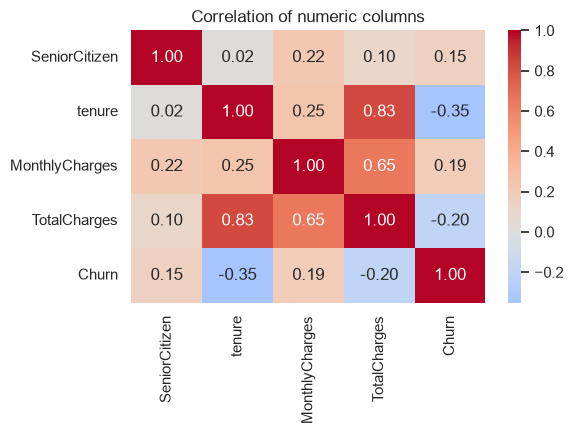

corr(TotalCharges, tenure x MonthlyCharges): 0.9996
median % gap: 2.0


In [9]:
# correlations and the TotalCharges trap
numeric = df[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", TARGET]]
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation of numeric columns")
plt.tight_layout()
fig.savefig(FIG_DIR / "correlations.png", dpi=150, bbox_inches="tight")
plt.show()

billed = df[df["tenure"] > 0]
expected = billed["tenure"] * billed["MonthlyCharges"]
print("corr(TotalCharges, tenure x MonthlyCharges):",
      round(billed["TotalCharges"].corr(expected), 4))
print("median % gap:",
      round(((billed["TotalCharges"] - expected).abs() / expected).median() * 100, 2))

## Five insights
1. (contract) ...
2. (tenure) ...
3. (internet type / services) ...
4. (payment method) ...
5. (something that surprised me) ...

Caveats: these are associations in one company's data, not proven causes.